Partial lecture notes of class 10 on Significance testing. The full powerpoint lecture is on Onedrive and saved into this directory

In [3]:
import pandas as pd
import seaborn as sns
from statsmodels.formula.api import ols

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

## Ground finch only

In [11]:
beaks = pd.read_csv('../../Datasets/finches beak depth.csv')
beaks

,year,depth
0,1976,9.4
1,1976,10.3
2,1976,11.2
3,1976,9.2
4,1976,10.2
...,...,...
130,1978,10.2
131,1978,8.9
132,1978,11.2
133,1978,10.1


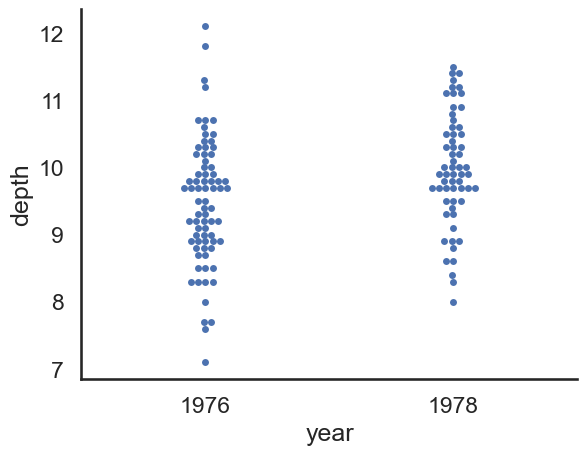

In [14]:
sns.swarmplot(data=beaks, x='year', y='depth');

## Ground and Cactus finches

"species" is a categorical variable 

It has two levels of "Ground finch" and "Cactus finch"

In [25]:
beaks = pd.read_csv('../../Datasets/species_beak_depths.csv')
beaks

,year,depth,species
0,1976,10.5,Cactus finch
1,1976,11.5,Cactus finch
2,1976,12.4,Cactus finch
3,1976,10.3,Cactus finch
4,1976,11.4,Cactus finch
...,...,...,...
265,1978,10.2,Ground finch
266,1978,8.9,Ground finch
267,1978,11.2,Ground finch
268,1978,10.1,Ground finch


Have used box plots as easier to see the differences.

Cactus finch beak depths are on average about 1 mm larger then Ground finches

Beak depths increased by about 0.5 mm for both species in 1978.

In [27]:
beaks['year'] = beaks['year'].astype('category')

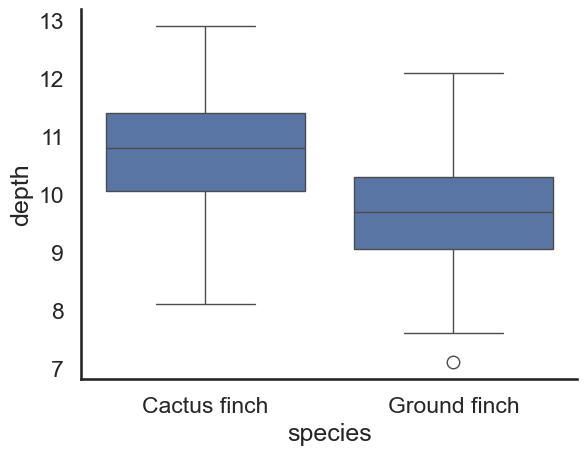

In [29]:
sns.boxplot(data=beaks, x='species', y='depth');

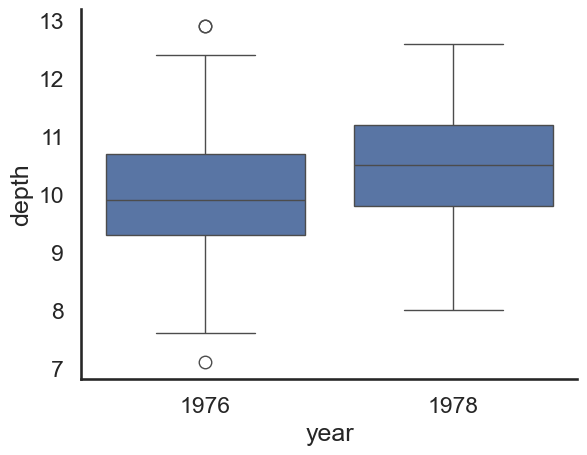

In [31]:
sns.boxplot(data=beaks, x='year', y='depth');

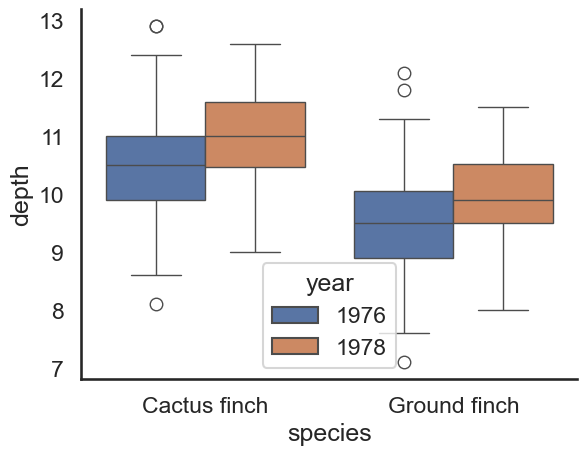

In [6]:
beaks['year'] = beaks['year'].astype('category')
sns.boxplot(data=beaks, hue='year', y='depth', x='species');

## Model the data

Our model of the data is 

> Mean beak depth **is related to** year *and* species


```python
formula = 'depth ~ C(year) + species'
```

The plus sign means "and" not "add" as it would in a mathematical formula.

## Code and fit the model

In [7]:
formula = 'depth ~ C(year) + species'
fit = ols(formula, beaks).fit()
fit.summary().tables[1]



,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,10.5043,0.092,113.603,0.000,10.322,10.686
C(year)[T.1978],0.4853,0.111,4.364,0.000,0.266,0.704
species[T.Ground finch],-1.0126,0.111,-9.162,0.000,-1.230,-0.795


In [8]:
fit.pvalues

Intercept                  4.523284e-228
C(year)[T.1978]             1.824523e-05
species[T.Ground finch]     1.390314e-17
dtype: float64

## Reference levels

There are two categorical variables and each has a reference level. Python automatically choses levels which come first numerically or alphabetically. So, in this case the reference levels are `1976` for `year` and `Cactus finch` for `species`.


### Interpret the table

The value of `Intercept` is 10.5 mm, which is the average beak depth of Cactus finches in 1976 (the reference levels). 

The value of `C(year)[T.1978]` is 0.49 mm, which is the mean difference between 1976 and 1978 across both finch species. The is statistically significant with a *P* = 1.8 x 10<sup>-5</sup>, so highly incompatible with the null of no difference. Its 95% CI is [0.27, 0.70] mm. **In English, beak depths increased on average by about half a millimetre from 1976 to 1978.**

The value of `species[T.Ground finch]` is -1.01 mm, which is the mean difference between Cactus finches and Ground finches in both years. This is statistically significant with a *P* = 1.4 x 10<sup>-17</sup> and a 95% CI of [-1.23, -0.80] mm. So highly incompatible with null of no difference. **In English, Cactus finch beak depths are about one millimetre longer than Ground finch beak depths in both years.**

### Did the increase in beak depths differ between species?

This analysis has assumed that beak depths increased equally for both species from 1976 to 1978. In other words beak depths increased by half a millimetre for Ground finches and half a millimetre for Cactus finches. 

But that might not be the case.

We need to examine if the increase in beak depths differed between species. To do this we need to add another term to our model formula:

```python
formula = 'depth ~ C(year) + species + C(year):species'
```

In linear modelling terminology, the additional term `C(year):species` is called an interaction effect. The terms `C(year)` and `species` are called main effects.

When we fit this model to the data, the size of the interaction term tells us the **difference** in the increase in beak depths between the two species. If this difference is zero, then the increase in beak depths was the same for both species (i.e., 0.49 mm). But if this difference is significantly different from zero, then the increase in beak depths was larger for one species than the other.

Let's fit this model.

In [12]:
formula2 = 'depth ~ C(year) + species + C(year):species'
fit2 = ols(formula2, beaks).fit()
fit2.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,10.5080,0.105,100.037,0.000,10.301,10.715
C(year)[T.1978],0.4770,0.158,3.027,0.003,0.167,0.787
species[T.Ground finch],-1.0200,0.149,-6.866,0.000,-1.312,-0.728
C(year)[T.1978]:species[T.Ground finch],0.0167,0.223,0.075,0.940,-0.422,0.455


The value of the interaction term `C(year)[T.1978]:species[T.Ground finch]` is 0.02 mm. But the 95% CI contains zero ([-0.42, 0.46] mm) and *P* = 0.94, so a non-significant difference. The data are, therefore, compatible with the null hypothesis that the increase in beak depths was the same for both species.

If you compare this table with the previous one, you'll notice that all of the values are different, including the *P* values and the 95% CIs. So which table should we use to report the final conclusions? 

Well, because the interaction term in the second model was non-significant, it is not telling us anything new about the data. We should therefore discard this model and use the first, simpler model for our conclusions.

This principle is called Occam's razor. Among competing hypotheses, the one with the fewest assumptions should be selected. This principle prioritises simplicity in explanations or models.

## Report the outcome of the test

For this we need the total number of finches sampled to report the degrees of freedom of the *t*-test.

In [10]:
beaks['depth'].count()

270

> Cactus finch beak depths are on average 1.0 mm (95% CI: [0.80, 1.23] mm) longer than Ground finch beak depths ($t_{268}=9.2$, $P=1.4\times 10^{-17}$). Between 1976 and 1978 beak depths of both species increased by 0.49 mm (95% CI: [0.27, 0.70] mm, $t_{268}=4.4$, $P=1.8\times 10^{-5}$).